# Steganaliz: LSB Steganografi Tespiti — Xu-Net CNN

**Veri Seti:** ALASKA2 — IEEE WIFS 2020 (Troyes Teknoloji Üniversitesi)  
**Model:** Xu-Net CNN (Guanshuo Xu et al., 2016)  
**Yöntem:** LSB (Least Significant Bit) Steganografi Tespiti  
**Referans:** Buluş, E. (2025). Investigation of steganalysis performance of selected steganography methods with deep learning models. *Gazi University Journal of Science*, 40(1), 443-453.

## Proje Akışı
1. Kütüphane kurulumu  
2. Google Drive bağlantısı  
3. Kaggle API & veri indirme  
4. Zip açma & kontrol  
5. Subset oluşturma  
6. LSB steganografi uygulama  
7. Veri seti görsel inceleme  
8. Temel görüntü işleme  
9. LSB piksel analizi  
10. DataLoader hazırlama  
11. Xu-Net mimarisi  
12. Model eğitimi  
13. Eğitim grafikleri  
14. Test & metrikler  
15. ROC eğrisi  
16. Grad-CAM  
17. Yanlış tahminler  
18. Sonuç tablosu

## Steganografi Nedir?
Steganografi, bir verinin başka bir verinin içine **fark edilmeyecek şekilde gizlenmesi** sanatıdır.  
Bu projede LSB yöntemi kullanılmaktadır: Her pikselin en önemsiz biti değiştirilerek gizli veri saklanır.  
Maksimum piksel değişimi **1 birim** — insan gözü bu farkı göremez, Xu-Net görebilir mi?

## 1. Kütüphane Kurulumu

In [ ]:
!pip install kaggle tqdm grad-cam seaborn -q

import os, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageFilter
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              roc_auc_score, roc_curve, auc)

SEED       = 42
IMG_SIZE   = 256
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Cihaz : {device}")
if torch.cuda.is_available():
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
print("Kütüphaneler hazır")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 84.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Cihaz : cuda
GPU   : Tesla T4
Kütüphaneler hazır


## 2. Google Drive Bağlantısı

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR  = '/content/drive/MyDrive/steganalysis_project'
MODELS_DIR = f'{DRIVE_DIR}/models'
CIKTI_DIR  = '/content/ciktilar'

for d in [DRIVE_DIR, MODELS_DIR, CIKTI_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Drive: {DRIVE_DIR}")
print("Drive bağlandı")

Mounted at /content/drive
Drive: /content/drive/MyDrive/steganalysis_project
Drive bağlandı


## 3. Kaggle API Kurulumu
`kaggle.com → Settings → API → Create New Token → kaggle.json` dosyasından bilgileri alın.

In [ ]:
import os

KAGGLE_USERNAME = "KULLANICI_ADINIZ"
KAGGLE_KEY      = "KAGGLE_API_ANAHTARINIZ"

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    f.write(f'{{"username":"{KAGGLE_USERNAME}","key":"{KAGGLE_KEY}"}}')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!pip install kaggle -q
!kaggle competitions files alaska2-image-steganalysis --page-size 1 -q
print("Kaggle API hazır")

Next Page Token = CfDJ8G82xNY93phHtA6xMwIf8xOAMXYavQ40qqgU4qYgYaW2e8XwjZHRoTKF1egic8TD1goR40JYNaFHMOqsOexxOZBEkfVwurf8H2rTfGGXh4kunGHPLhIoQv485cYSUN8sKF8jS26emobO
name                   size  creationDate                
---------------  ----------  --------------------------  
Cover/00001.jpg      102134  2020-04-16 22:14:01.834000  
Kaggle API hazır


## 4. Veri İndirme & Zip Açma

In [ ]:
import os

os.makedirs('/content/data', exist_ok=True)
print("Veri indiriliyor... (~30 GB)")
!kaggle competitions download alaska2-image-steganalysis -p /content/data/
print("İndirme tamamlandı, zip açılıyor...")
!unzip -q /content/data/alaska2-image-steganalysis.zip -d /content/data/
os.remove('/content/data/alaska2-image-steganalysis.zip')
print("Zip silindi")

for klasor in ['Cover', 'JMiPOD', 'JUNIWARD', 'UERD', 'Test']:
    sayi = len(os.listdir(f'/content/data/{klasor}'))
    print(f"  {klasor:12s} → {sayi:,} görüntü")
print("Veri hazır")

Veri indiriliyor... (~30 GB)
100% 30.0G/30.0G [06:04<00:00, 88.2MB/s]

İndirme tamamlandı, zip açılıyor...
Zip silindi
  Cover        → 75,000 görüntü
  JMiPOD       → 75,000 görüntü
  JUNIWARD     → 75,000 görüntü
  UERD         → 75,000 görüntü
  Test         → 5,000 görüntü
Veri hazır


## 5. Subset Oluşturma
75,000 görüntüden 2,000 tanesi rastgele seçiliyor. Train %70 — Val %15 — Test %15.

In [28]:
import os, shutil, random
from sklearn.model_selection import train_test_split

random.seed(42)

kaynak_cover = '/content/data/Cover'
kaynak_stego = '/content/data/JMiPOD'
hedef        = '/content/subset'

if os.path.exists(hedef):
    shutil.rmtree(hedef)

for bolum in ['train', 'val', 'test']:
    for sinif in ['cover', 'stego']:
        os.makedirs(f'{hedef}/{bolum}/{sinif}', exist_ok=True)

ortak   = sorted(set(os.listdir(kaynak_cover)) & set(os.listdir(kaynak_stego)))
secilen = random.sample(ortak, 2000)

tum_veri = [(f, 0) for f in secilen] + [(f, 1) for f in secilen]

train, temp = train_test_split(tum_veri, test_size=0.30, random_state=42,
                                stratify=[x[1] for x in tum_veri])
val, test   = train_test_split(temp, test_size=0.50, random_state=42,
                                stratify=[x[1] for x in temp])

train_set = set(train)
val_set   = set(val)

print("Görüntüler kopyalanıyor...")
for dosya, etiket in tum_veri:
    sinif  = 'cover' if etiket == 0 else 'stego'
    kaynak = kaynak_cover if etiket == 0 else kaynak_stego
    bolum  = 'train' if (dosya, etiket) in train_set else              'val'   if (dosya, etiket) in val_set   else 'test'
    shutil.copy(os.path.join(kaynak, dosya), f'{hedef}/{bolum}/{sinif}/{dosya}')

print("\nSubset hazır")
for bolum in ['train', 'val', 'test']:
    for sinif in ['cover', 'stego']:
        sayi = len(os.listdir(f'{hedef}/{bolum}/{sinif}'))
        print(f"  {bolum:6s}/{sinif:6s} → {sayi} görüntü")

Görüntüler kopyalanıyor...

Subset hazır
  train /cover  → 1400 görüntü
  train /stego  → 1400 görüntü
  val   /cover  → 300 görüntü
  val   /stego  → 300 görüntü
  test  /cover  → 300 görüntü
  test  /stego  → 300 görüntü


## 6. LSB Steganografi Uygulama
Cover görüntülerine LSB yöntemiyle gizli veri saklanıyor. Kayıpsız format için PNG kullanılıyor.

In [29]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

def lsb_uygula(kaynak_yol, hedef_yol):
    goruntu = Image.open(kaynak_yol).convert('L')
    piksel  = np.array(goruntu, dtype=np.uint8)
    toplam  = piksel.size
    mesaj   = np.zeros(toplam, dtype=np.uint8)
    mesaj[:toplam // 2] = 1
    np.random.shuffle(mesaj)
    duz   = piksel.flatten()
    duz   = (duz & 0xFE) | mesaj
    stego = duz.reshape(piksel.shape)
    Image.fromarray(stego).save(hedef_yol)

lsb_hedef     = '/content/lsb_subset'
subset_kaynak = '/content/subset'

for bolum in ['train', 'val', 'test']:
    k_cover = f'{subset_kaynak}/{bolum}/cover'
    h_cover = f'{lsb_hedef}/{bolum}/cover'
    h_stego = f'{lsb_hedef}/{bolum}/stego'
    os.makedirs(h_cover, exist_ok=True)
    os.makedirs(h_stego, exist_ok=True)
    dosyalar = os.listdir(k_cover)
    print(f"{bolum} işleniyor — {len(dosyalar)} görüntü")
    for dosya in tqdm(dosyalar):
        kaynak = os.path.join(k_cover, dosya)
        isim   = dosya.replace('.jpg', '.png')
        Image.open(kaynak).convert('L').save(f'{h_cover}/{isim}')
        lsb_uygula(kaynak, f'{h_stego}/{isim}')

print("\nLSB veri seti hazır")
for b in ['train','val','test']:
    nc = len(os.listdir(f'{lsb_hedef}/{b}/cover'))
    ns = len(os.listdir(f'{lsb_hedef}/{b}/stego'))
    print(f"  {b:6s} → cover: {nc}, stego: {ns}")

train işleniyor — 1400 görüntü


100%|██████████| 1400/1400 [02:06<00:00, 11.10it/s]


val işleniyor — 300 görüntü


100%|██████████| 300/300 [00:26<00:00, 11.40it/s]


test işleniyor — 300 görüntü


100%|██████████| 300/300 [00:25<00:00, 11.54it/s]


LSB veri seti hazır
  train  → cover: 1400, stego: 1400
  val    → cover: 558, stego: 558
  test   → cover: 551, stego: 551


## 7. Veri Seti Görsel İnceleme
Cover (temiz) ve Stego (gizli veri saklı) görüntüler karşılaştırılıyor.

Cover  : 75,000 görüntü
Stego  : 75,000 görüntü
Boyut  : (512, 512)


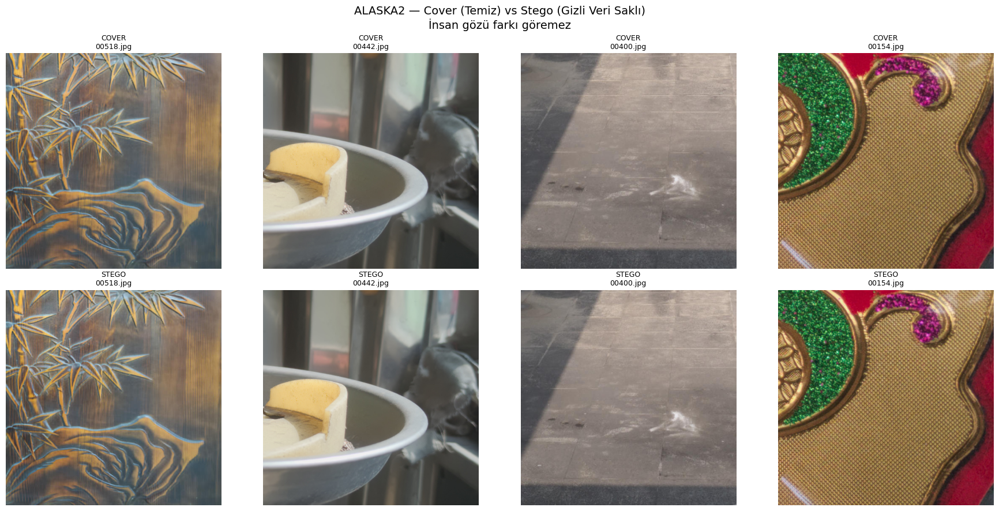

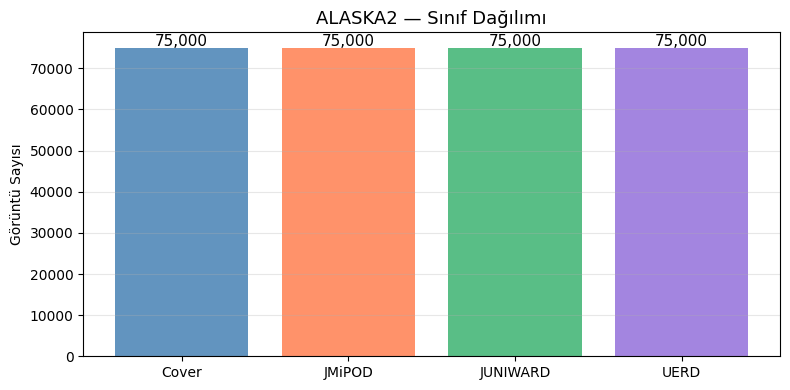

Görseller kaydedildi


In [30]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

COVER_DIR = '/content/data/Cover'
STEGO_DIR = '/content/data/JMiPOD'
CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

cover_dosyalar = sorted(os.listdir(COVER_DIR))
stego_dosyalar = sorted(os.listdir(STEGO_DIR))
ortak_list = sorted(set(cover_dosyalar) & set(stego_dosyalar))

print(f"Cover  : {len(cover_dosyalar):,} görüntü")
print(f"Stego  : {len(stego_dosyalar):,} görüntü")
print(f"Boyut  : {Image.open(f'{COVER_DIR}/{cover_dosyalar[0]}').size}")

# 4 çift Cover vs Stego
secilen = random.sample(ortak_list[:500], 4)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, dosya in enumerate(secilen):
    c = Image.open(f'{COVER_DIR}/{dosya}').convert('RGB')
    s = Image.open(f'{STEGO_DIR}/{dosya}').convert('RGB')
    axes[0][i].imshow(c); axes[0][i].set_title(f'COVER\n{dosya}', fontsize=9); axes[0][i].axis('off')
    axes[1][i].imshow(s); axes[1][i].set_title(f'STEGO\n{dosya}', fontsize=9); axes[1][i].axis('off')
axes[0][0].set_ylabel('Cover', fontsize=13, labelpad=10)
axes[1][0].set_ylabel('Stego', fontsize=13, labelpad=10)
plt.suptitle('ALASKA2 — Cover (Temiz) vs Stego (Gizli Veri Saklı)\nİnsan gözü farkı göremez', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/01_cover_vs_stego.png', dpi=150, bbox_inches='tight')
plt.show()

# Sınıf dağılımı
siniflar = ['Cover', 'JMiPOD', 'JUNIWARD', 'UERD']
sayilar  = [len(os.listdir(f'/content/data/{s}')) for s in siniflar]
fig, ax  = plt.subplots(figsize=(8, 4))
bars = ax.bar(siniflar, sayilar, color=['steelblue','coral','mediumseagreen','mediumpurple'], alpha=0.85)
for bar, sayi in zip(bars, sayilar):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+500, f'{sayi:,}', ha='center', fontsize=11)
ax.set_title('ALASKA2 — Sınıf Dağılımı', fontsize=13)
ax.set_ylabel('Görüntü Sayısı'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/02_sinif_dagilimi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Görseller kaydedildi")

## 8. Temel Görüntü İşleme
Tek görüntü üzerinde gri dönüşüm, filtreler, kanal analizi ve histogramlar.

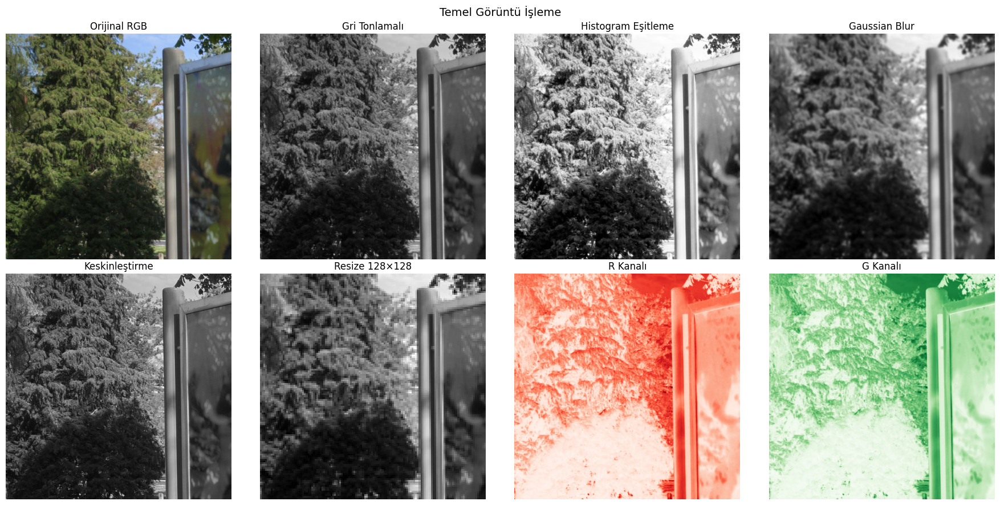

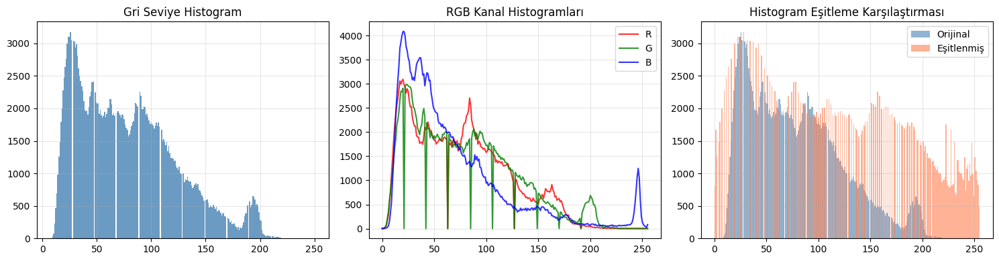

Kaydedildi


In [31]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter

COVER_DIR = '/content/data/Cover'
CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)
cover_dosyalar = sorted(os.listdir(COVER_DIR))

dosya   = cover_dosyalar[0]
c_yol   = f'{COVER_DIR}/{dosya}'
c_rgb   = np.array(Image.open(c_yol).convert('RGB'))
c_gri   = np.array(Image.open(c_yol).convert('L'))

gri_eq  = np.array(ImageOps.equalize(Image.fromarray(c_gri)))
bulanik = np.array(Image.fromarray(c_gri).filter(ImageFilter.GaussianBlur(2)))
keskin  = np.array(Image.fromarray(c_gri).filter(ImageFilter.SHARPEN))
resized = np.array(Image.fromarray(c_gri).resize((128, 128)))

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes[0][0].imshow(c_rgb);            axes[0][0].set_title('Orijinal RGB');        axes[0][0].axis('off')
axes[0][1].imshow(c_gri, cmap='gray'); axes[0][1].set_title('Gri Tonlamalı');    axes[0][1].axis('off')
axes[0][2].imshow(gri_eq, cmap='gray'); axes[0][2].set_title('Histogram Eşitleme'); axes[0][2].axis('off')
axes[0][3].imshow(bulanik, cmap='gray'); axes[0][3].set_title('Gaussian Blur');   axes[0][3].axis('off')
axes[1][0].imshow(keskin, cmap='gray'); axes[1][0].set_title('Keskinleştirme');   axes[1][0].axis('off')
axes[1][1].imshow(resized, cmap='gray'); axes[1][1].set_title('Resize 128×128'); axes[1][1].axis('off')
axes[1][2].imshow(c_rgb[:,:,0], cmap='Reds');   axes[1][2].set_title('R Kanalı'); axes[1][2].axis('off')
axes[1][3].imshow(c_rgb[:,:,1], cmap='Greens'); axes[1][3].set_title('G Kanalı'); axes[1][3].axis('off')
plt.suptitle('Temel Görüntü İşleme', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/03_temel_goruntu.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(c_gri.ravel(), bins=256, color='steelblue', alpha=0.8)
axes[0].set_title('Gri Seviye Histogram'); axes[0].grid(True, alpha=0.3)
axes[1].plot(np.histogram(c_rgb[:,:,0].ravel(),256)[0], color='red',   label='R', alpha=0.8)
axes[1].plot(np.histogram(c_rgb[:,:,1].ravel(),256)[0], color='green', label='G', alpha=0.8)
axes[1].plot(np.histogram(c_rgb[:,:,2].ravel(),256)[0], color='blue',  label='B', alpha=0.8)
axes[1].set_title('RGB Kanal Histogramları'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[2].hist(c_gri.ravel(), bins=256, alpha=0.6, color='steelblue', label='Orijinal')
axes[2].hist(gri_eq.ravel(), bins=256, alpha=0.6, color='coral', label='Eşitlenmiş')
axes[2].set_title('Histogram Eşitleme Karşılaştırması'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/04_histogramlar.png', dpi=150, bbox_inches='tight')
plt.show()
print("Kaydedildi")

## 9. LSB Piksel Analizi
Cover ve Stego arasındaki piksel düzeyindeki farkları görselleştirme.

Maksimum piksel farkı : 1
Değişen piksel        : 131,195 / 262,144  (%50.0)


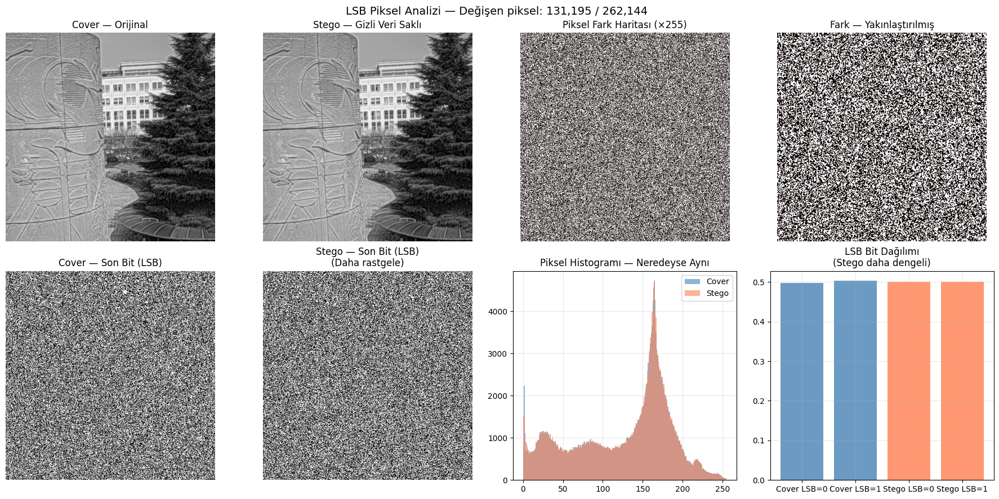

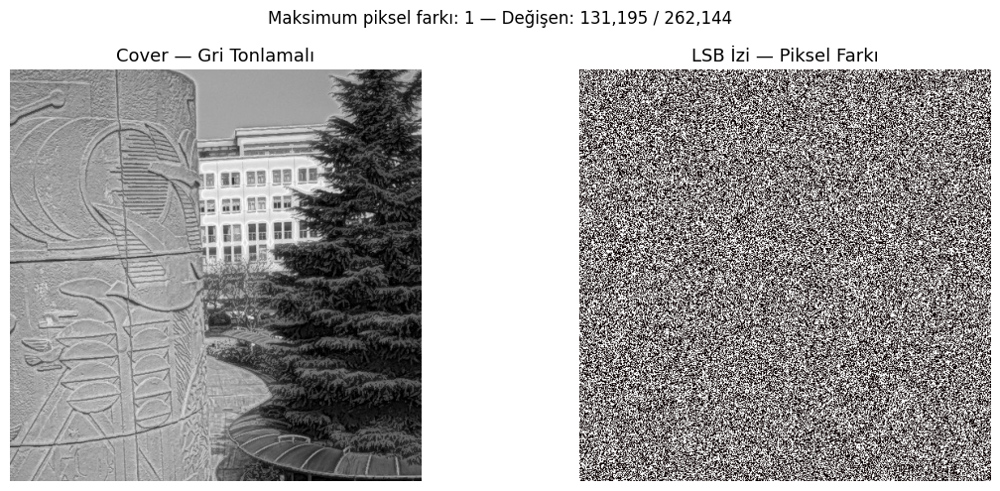

Kaydedildi


In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

COVER_DIR = '/content/data/Cover'
STEGO_DIR = '/content/data/JMiPOD'
CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

# Aynı görüntüden cover ve stego al
cover_dosyalar = sorted(os.listdir(COVER_DIR))
stego_dosyalar = sorted(os.listdir(STEGO_DIR))
ortak_list = sorted(set(cover_dosyalar) & set(stego_dosyalar))
dosya = ortak_list[0]

c_gri = np.array(Image.open(f'{COVER_DIR}/{dosya}').convert('L'))
s_gri = np.array(Image.open(f'{STEGO_DIR}/{dosya}').convert('L'))

# LSB uygulama ile üretilmiş stego da göster
cover_gri = np.array(Image.open(f'/content/subset/test/cover/{sorted(os.listdir("/content/subset/test/cover"))[0]}').convert('L'), dtype=np.uint8)
np.random.seed(42)
toplam = cover_gri.size
mesaj  = np.zeros(toplam, dtype=np.uint8)
mesaj[:toplam // 2] = 1
np.random.shuffle(mesaj)
stego_gri = ((cover_gri.flatten() & 0xFE) | mesaj).reshape(cover_gri.shape)

fark          = np.abs(cover_gri.astype(int) - stego_gri.astype(int))
fark_gosterim = np.clip(fark * 255, 0, 255).astype(np.uint8)
cover_lsb     = (cover_gri & 1) * 255
stego_lsb     = (stego_gri & 1) * 255

print(f"Maksimum piksel farkı : {fark.max()}")
print(f"Değişen piksel        : {(fark>0).sum():,} / {fark.size:,}  (%{100*(fark>0).sum()/fark.size:.1f})")

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes[0][0].imshow(cover_gri, cmap='gray'); axes[0][0].set_title('Cover — Orijinal'); axes[0][0].axis('off')
axes[0][1].imshow(stego_gri, cmap='gray'); axes[0][1].set_title('Stego — Gizli Veri Saklı'); axes[0][1].axis('off')
axes[0][2].imshow(fark_gosterim, cmap='hot'); axes[0][2].set_title('Piksel Fark Haritası (×255)'); axes[0][2].axis('off')
h, w = fark.shape
axes[0][3].imshow(fark_gosterim[h//4:3*h//4, w//4:3*w//4], cmap='hot')
axes[0][3].set_title('Fark — Yakınlaştırılmış'); axes[0][3].axis('off')
axes[1][0].imshow(cover_lsb, cmap='gray'); axes[1][0].set_title('Cover — Son Bit (LSB)'); axes[1][0].axis('off')
axes[1][1].imshow(stego_lsb, cmap='gray'); axes[1][1].set_title('Stego — Son Bit (LSB)\n(Daha rastgele)'); axes[1][1].axis('off')
axes[1][2].hist(cover_gri.ravel(), bins=256, alpha=0.6, color='steelblue', label='Cover')
axes[1][2].hist(stego_gri.ravel(), bins=256, alpha=0.6, color='coral', label='Stego')
axes[1][2].set_title('Piksel Histogramı — Neredeyse Aynı'); axes[1][2].legend(); axes[1][2].grid(True, alpha=0.3)
clsb = (cover_gri & 1).mean(); slsb = (stego_gri & 1).mean()
axes[1][3].bar(['Cover LSB=0','Cover LSB=1','Stego LSB=0','Stego LSB=1'],
               [1-clsb, clsb, 1-slsb, slsb],
               color=['steelblue','steelblue','coral','coral'], alpha=0.8)
axes[1][3].set_title('LSB Bit Dağılımı\n(Stego daha dengeli)'); axes[1][3].grid(True, alpha=0.3)
plt.suptitle(f'LSB Piksel Analizi — Değişen piksel: {(fark>0).sum():,} / {fark.size:,}', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/05_lsb_analiz.png', dpi=150, bbox_inches='tight')
plt.show()

# LSB fark haritası ayrıca
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))
axes2[0].imshow(cover_gri, cmap='gray'); axes2[0].set_title('Cover — Gri Tonlamalı', fontsize=13); axes2[0].axis('off')
axes2[1].imshow(fark_gosterim, cmap='hot'); axes2[1].set_title('LSB İzi — Piksel Farkı', fontsize=13); axes2[1].axis('off')
plt.suptitle(f'Maksimum piksel farkı: {fark.max()} — Değişen: {(fark>0).sum():,} / {fark.size:,}', fontsize=12)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/06_lsb_fark_haritasi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Kaydedildi")

## 10. DataLoader Hazırlama

Train  : 2,800 görüntü
Val    : 1,116 görüntü
Test   : 1,102 görüntü
Sınıflar: ['cover', 'stego']


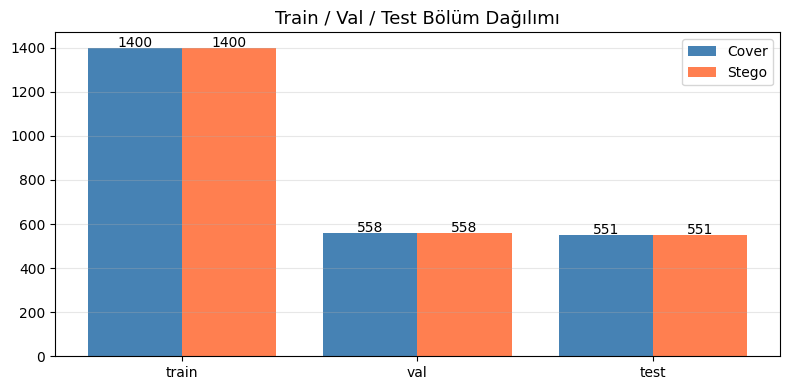

DataLoader hazır


In [33]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

donusum = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

lsb_path = '/content/lsb_subset'

train_loader = DataLoader(datasets.ImageFolder(f'{lsb_path}/train', transform=donusum),
                          batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(datasets.ImageFolder(f'{lsb_path}/val',   transform=donusum),
                          batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(datasets.ImageFolder(f'{lsb_path}/test',  transform=donusum),
                          batch_size=32, shuffle=False, num_workers=2)

print(f"Train  : {len(train_loader.dataset):,} görüntü")
print(f"Val    : {len(val_loader.dataset):,} görüntü")
print(f"Test   : {len(test_loader.dataset):,} görüntü")
print(f"Sınıflar: {train_loader.dataset.classes}")

# Bölüm dağılımı grafiği
import os, numpy as np, matplotlib.pyplot as plt
CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)
bolumler = ['train','val','test']
cover_s  = [len(os.listdir(f'{lsb_path}/{b}/cover')) for b in bolumler]
stego_s  = [len(os.listdir(f'{lsb_path}/{b}/stego')) for b in bolumler]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x-0.2, cover_s, 0.4, label='Cover', color='steelblue')
b2 = ax.bar(x+0.2, stego_s, 0.4, label='Stego', color='coral')
for bar in list(b1)+list(b2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5, str(int(bar.get_height())), ha='center', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(bolumler); ax.legend(); ax.grid(axis='y', alpha=0.3)
ax.set_title('Train / Val / Test Bölüm Dağılımı', fontsize=13)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/07_bolum_dagilim.png', dpi=150, bbox_inches='tight')
plt.show()
print("DataLoader hazır")

## 11. Xu-Net Mimarisi
Steganaliz için özel tasarlanmış CNN. HPF filtresiyle zayıf stego izlerini yakalar.

Cihaz              : cuda
GPU                : Tesla T4
Toplam parametre   : 48,459
Eğitilen parametre : 48,434
Sabit (HPF)        : 25


/tmp/ipykernel_1302/3976693892.py:61: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((i*1.8, 0.2), 1.4, 0.6, color=renk, alpha=0.85, linewidth=1.5, edgecolor='black'))


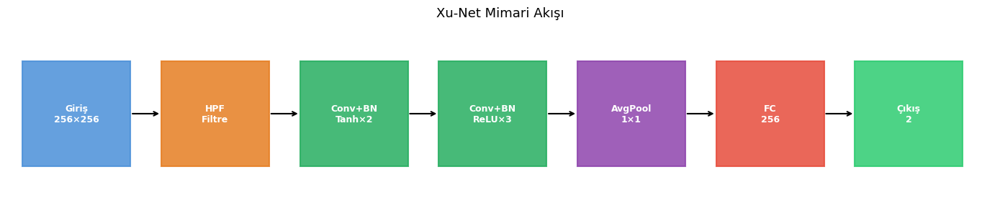

Xu-Net hazır


In [34]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CIKTI_DIR = '/content/ciktilar'

class XuNet(nn.Module):
    def __init__(self):
        super(XuNet, self).__init__()
        self.hpf = nn.Conv2d(1, 1, kernel_size=5, padding=2, bias=False)
        hpf_agirlik = torch.tensor([
            [-1,  2, -2,  2, -1],
            [ 2, -6,  8, -6,  2],
            [-2,  8,-12,  8, -2],
            [ 2, -6,  8, -6,  2],
            [-1,  2, -2,  2, -1]
        ], dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 12.0
        self.hpf.weight = nn.Parameter(hpf_agirlik, requires_grad=False)

        self.ozellikler = nn.Sequential(
            nn.Conv2d(1, 8,   kernel_size=5, padding=2), nn.BatchNorm2d(8),   nn.Tanh(),
            nn.AvgPool2d(5, stride=2, padding=2),
            nn.Conv2d(8, 16,  kernel_size=5, padding=2), nn.BatchNorm2d(16),  nn.Tanh(),
            nn.AvgPool2d(5, stride=2, padding=2),
            nn.Conv2d(16, 32, kernel_size=1),            nn.BatchNorm2d(32),  nn.ReLU(),
            nn.AvgPool2d(5, stride=2, padding=2),
            nn.Conv2d(32, 64, kernel_size=1),            nn.BatchNorm2d(64),  nn.ReLU(),
            nn.AvgPool2d(5, stride=2, padding=2),
            nn.Conv2d(64, 128, kernel_size=1),           nn.BatchNorm2d(128), nn.ReLU(),
        )
        self.siniflandirici = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.hpf(x)
        x = self.ozellikler(x)
        x = self.siniflandirici(x)
        return x

model = XuNet().to(device)
toplam   = sum(p.numel() for p in model.parameters())
egitilen = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Cihaz              : {device}")
if torch.cuda.is_available():
    print(f"GPU                : {torch.cuda.get_device_name(0)}")
print(f"Toplam parametre   : {toplam:,}")
print(f"Eğitilen parametre : {egitilen:,}")
print(f"Sabit (HPF)        : {toplam-egitilen:,}")

# Mimari diyagramı
katmanlar = ['Giriş\n256×256','HPF\nFiltre','Conv+BN\nTanh×2','Conv+BN\nReLU×3','AvgPool\n1×1','FC\n256','Çıkış\n2']
renkler   = ['#4A90D9','#E67E22','#27AE60','#27AE60','#8E44AD','#E74C3C','#2ECC71']
fig, ax   = plt.subplots(figsize=(14, 3))
for i, (kat, renk) in enumerate(zip(katmanlar, renkler)):
    ax.add_patch(plt.Rectangle((i*1.8, 0.2), 1.4, 0.6, color=renk, alpha=0.85, linewidth=1.5, edgecolor='black'))
    ax.text(i*1.8+0.7, 0.5, kat, ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    if i < len(katmanlar)-1:
        ax.annotate('', xy=((i+1)*1.8, 0.5), xytext=(i*1.8+1.4, 0.5),
                    arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
ax.set_xlim(-0.2, len(katmanlar)*1.8); ax.set_ylim(0, 1); ax.axis('off')
ax.set_title('Xu-Net Mimari Akışı', fontsize=13, pad=10)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/08_xunet_mimari.png', dpi=150, bbox_inches='tight')
plt.show()
print("Xu-Net hazır")

## 12. Model Eğitimi

In [39]:
import torch
import torch.nn as nn
import time
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DRIVE_DIR  = '/content/drive/MyDrive/steganalysis_project'
MODELS_DIR = f'{DRIVE_DIR}/models'
os.makedirs(MODELS_DIR, exist_ok=True)

kayip_fn  = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

def egit(model, loader, kayip_fn, optimizer, device):
    model.train()
    toplam_kayip, dogru, toplam = 0, 0, 0
    for goruntu, etiket in loader:
        goruntu, etiket = goruntu.to(device), etiket.to(device)
        optimizer.zero_grad()
        cikti = model(goruntu)
        kayip = kayip_fn(cikti, etiket)
        kayip.backward()
        optimizer.step()
        toplam_kayip += kayip.item()
        _, tahmin = cikti.max(1)
        dogru  += tahmin.eq(etiket).sum().item()
        toplam += etiket.size(0)
    return toplam_kayip / len(loader), 100. * dogru / toplam

def degerlendir(model, loader, kayip_fn, device):
    model.eval()
    toplam_kayip, dogru, toplam = 0, 0, 0
    with torch.no_grad():
        for goruntu, etiket in loader:
            goruntu, etiket = goruntu.to(device), etiket.to(device)
            cikti = model(goruntu)
            kayip = kayip_fn(cikti, etiket)
            toplam_kayip += kayip.item()
            _, tahmin = cikti.max(1)
            dogru  += tahmin.eq(etiket).sum().item()
            toplam += etiket.size(0)
    return toplam_kayip / len(loader), 100. * dogru / toplam

EPOCH_SAYISI = 20
en_iyi_dogruluk = 0
gecmis = {'train_kayip': [], 'val_kayip': [], 'train_dogru': [], 'val_dogru': []}

print(f"Eğitim başlıyor — {device} — {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print("-" * 70)

for epoch in range(1, EPOCH_SAYISI + 1):
    baslangic = time.time()
    train_kayip, train_dogru = egit(model, train_loader, kayip_fn, optimizer, device)
    val_kayip,   val_dogru   = degerlendir(model, val_loader, kayip_fn, device)
    scheduler.step(val_kayip)
    sure = time.time() - baslangic

    gecmis['train_kayip'].append(train_kayip)
    gecmis['val_kayip'].append(val_kayip)
    gecmis['train_dogru'].append(train_dogru)
    gecmis['val_dogru'].append(val_dogru)

    if val_dogru > en_iyi_dogruluk:
        en_iyi_dogruluk = val_dogru
        torch.save(model.state_dict(),
            f'{MODELS_DIR}/xunet_final.pth')
        durum = "* kaydedildi"
    else:
        durum = ""

    print(f"Epoch {epoch:2d}/{EPOCH_SAYISI} | "
          f"Train Kayıp: {train_kayip:.4f} Doğruluk: {train_dogru:.1f}% | "
          f"Val Kayıp: {val_kayip:.4f} Doğruluk: {val_dogru:.1f}% | "
          f"{sure:.0f}s {durum}")

print("-" * 70)
print(f"En iyi Val Doğruluğu: {en_iyi_dogruluk:.1f}%")

Eğitim başlıyor — cuda — Tesla T4
----------------------------------------------------------------------
Epoch  1/20 | Train Kayıp: 0.2806 Doğruluk: 86.2% | Val Kayıp: 2.7761 Doğruluk: 50.0% | 26s * kaydedildi
Epoch  2/20 | Train Kayıp: 0.2580 Doğruluk: 87.8% | Val Kayıp: 0.8565 Doğruluk: 50.8% | 26s * kaydedildi
Epoch  3/20 | Train Kayıp: 0.2379 Doğruluk: 88.4% | Val Kayıp: 2.6754 Doğruluk: 49.9% | 27s 
Epoch  4/20 | Train Kayıp: 0.2354 Doğruluk: 88.1% | Val Kayıp: 2.3832 Doğruluk: 49.8% | 25s 
Epoch  5/20 | Train Kayıp: 0.2183 Doğruluk: 88.6% | Val Kayıp: 1.6449 Doğruluk: 50.0% | 26s 
Epoch  6/20 | Train Kayıp: 0.2125 Doğruluk: 89.4% | Val Kayıp: 17.8315 Doğruluk: 50.0% | 27s 
Epoch  7/20 | Train Kayıp: 0.1982 Doğruluk: 90.8% | Val Kayıp: 4.1127 Doğruluk: 50.0% | 26s 
Epoch  8/20 | Train Kayıp: 0.1947 Doğruluk: 89.3% | Val Kayıp: 0.1935 Doğruluk: 91.8% | 25s * kaydedildi
Epoch  9/20 | Train Kayıp: 0.1913 Doğruluk: 90.9% | Val Kayıp: 5.0662 Doğruluk: 50.0% | 26s 
Epoch 10/20 | Train K

## 13. Eğitim Grafikleri

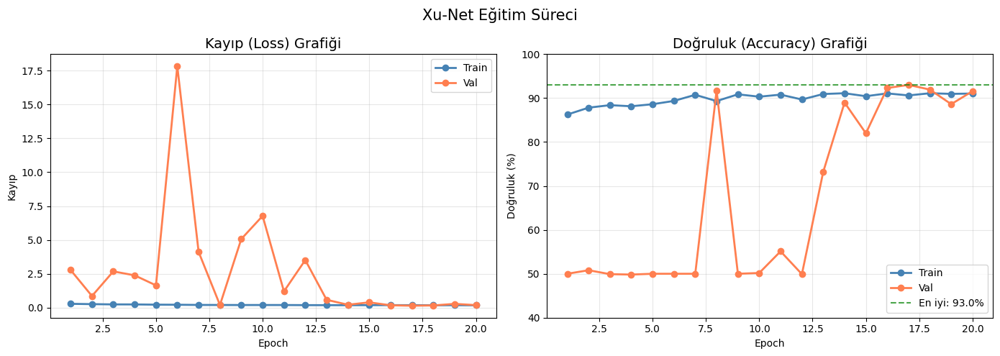

Eğitim grafiği kaydedildi 


In [41]:
import matplotlib.pyplot as plt
import os

CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

if 'gecmis' in locals() or 'gecmis' in globals():
    epochs = range(1, len(gecmis['train_kayip'])+1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, gecmis['train_kayip'], marker='o', label='Train', color='steelblue', linewidth=2)
    axes[0].plot(epochs, gecmis['val_kayip'],   marker='o', label='Val',   color='coral',     linewidth=2)
    axes[0].set_title('Kayıp (Loss) Grafiği', fontsize=14)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Kayıp')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, gecmis['train_dogru'], marker='o', label='Train', color='steelblue', linewidth=2)
    axes[1].plot(epochs, gecmis['val_dogru'],   marker='o', label='Val',   color='coral',     linewidth=2)
    axes[1].axhline(y=max(gecmis['val_dogru']), linestyle='--', color='green', alpha=0.7,
                    label=f'En iyi: {max(gecmis["val_dogru"]):.1f}%')
    axes[1].set_title('Doğruluk (Accuracy) Grafiği', fontsize=14)
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Doğruluk (%)')
    axes[1].set_ylim(40, 100); axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.suptitle('Xu-Net Eğitim Süreci', fontsize=15)
    plt.tight_layout()
    plt.savefig(f'{CIKTI_DIR}/09_egitim_grafigi.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Eğitim grafiği kaydedildi ")
else:
    print("- 'gecmis' hafızada yok — eğitim hücresini önce çalıştırın.")

## 14. Test & Metrikler
Model Drive'dan yükleniyor, test seti üzerinde değerlendiriliyor.

Model Drive'dan yüklendi

=== TEST SONUÇLARI ===
              precision    recall  f1-score   support

       Cover       0.94      0.92      0.93       551
       Stego       0.92      0.94      0.93       551

    accuracy                           0.93      1102
   macro avg       0.93      0.93      0.93      1102
weighted avg       0.93      0.93      0.93      1102

AUC-ROC: 0.9883


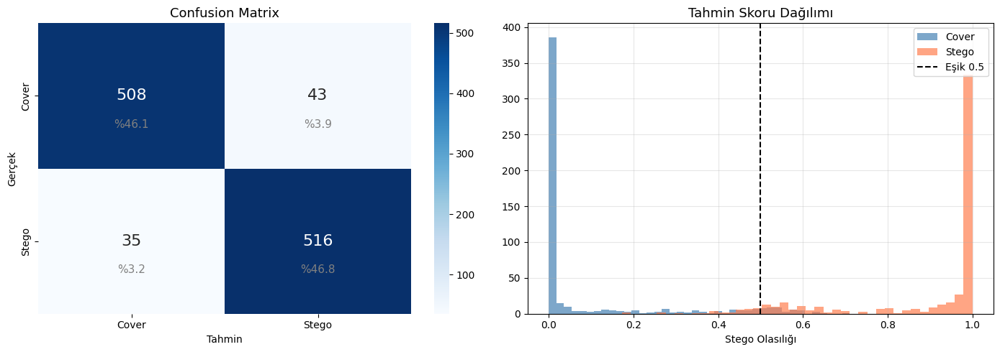

Confusion Matrix kaydedildi


In [42]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

CIKTI_DIR  = '/content/ciktilar'
MODELS_DIR = '/content/drive/MyDrive/steganalysis_project/models'
os.makedirs(CIKTI_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

try:
    model.load_state_dict(torch.load(f'{MODELS_DIR}/xunet_final.pth', map_location=device))
    print("Model Drive'dan yüklendi")
except Exception as e:
    print(f"Uyarı: {e} — hafızadaki model kullanılıyor")

model.eval()
tahminler, gercekler, olasiliklar = [], [], []

with torch.no_grad():
    for goruntu, etiket in test_loader:
        goruntu  = goruntu.to(device)
        cikti    = model(goruntu)
        olasilik = torch.softmax(cikti, dim=1)[:, 1]
        _, tahmin = cikti.max(1)
        tahminler.extend(tahmin.cpu().numpy())
        gercekler.extend(etiket.numpy())
        olasiliklar.extend(olasilik.cpu().numpy())

print("\n=== TEST SONUÇLARI ===")
print(classification_report(gercekler, tahminler, target_names=['Cover', 'Stego']))
print(f"AUC-ROC: {roc_auc_score(gercekler, olasiliklar):.4f}")

# Confusion Matrix
cm = confusion_matrix(gercekler, tahminler)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cover','Stego'], yticklabels=['Cover','Stego'],
            ax=axes[0], annot_kws={'size':16})
toplam = cm.sum()
for i in range(2):
    for j in range(2):
        axes[0].text(j+0.5, i+0.72, f'%{100*cm[i,j]/toplam:.1f}',
                     ha='center', fontsize=11, color='gray')
axes[0].set_title('Confusion Matrix', fontsize=13)
axes[0].set_ylabel('Gerçek'); axes[0].set_xlabel('Tahmin')

# Skor dağılımı
g_arr = np.array(gercekler); o_arr = np.array(olasiliklar)
axes[1].hist(o_arr[g_arr==0], bins=40, alpha=0.7, color='steelblue', label='Cover')
axes[1].hist(o_arr[g_arr==1], bins=40, alpha=0.7, color='coral', label='Stego')
axes[1].axvline(0.5, color='black', linestyle='--', label='Eşik 0.5')
axes[1].set_title('Tahmin Skoru Dağılımı', fontsize=13)
axes[1].set_xlabel('Stego Olasılığı'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/10_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion Matrix kaydedildi")

## 15. ROC Eğrisi
Modelin farklı eşik değerlerindeki performansı. AUC değeri 1.0'a ne kadar yakınsa model o kadar iyi.

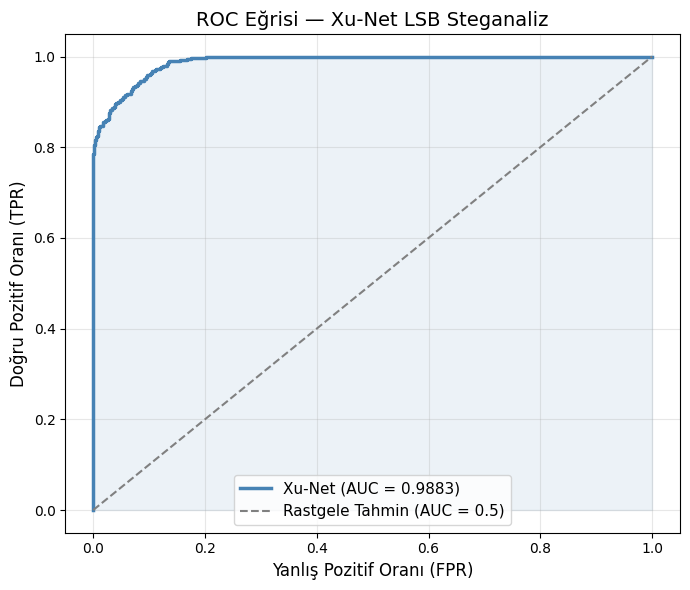

AUC-ROC: 0.9883
ROC eğrisi kaydedildi


In [43]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import os

CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

fpr, tpr, _ = roc_curve(gercekler, olasiliklar)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2.5, label=f'Xu-Net (AUC = {roc_auc_val:.4f})')
plt.fill_between(fpr, tpr, alpha=0.1, color='steelblue')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Rastgele Tahmin (AUC = 0.5)')
plt.xlabel('Yanlış Pozitif Oranı (FPR)', fontsize=12)
plt.ylabel('Doğru Pozitif Oranı (TPR)', fontsize=12)
plt.title('ROC Eğrisi — Xu-Net LSB Steganaliz', fontsize=14)
plt.legend(fontsize=11); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/11_roc_egrisi.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"AUC-ROC: {roc_auc_val:.4f}")
print("ROC eğrisi kaydedildi")

## 16. Grad-CAM — Model Nereye Baktı?
Kırmızı alan = modelin stego izi tespit ettiği bölge.

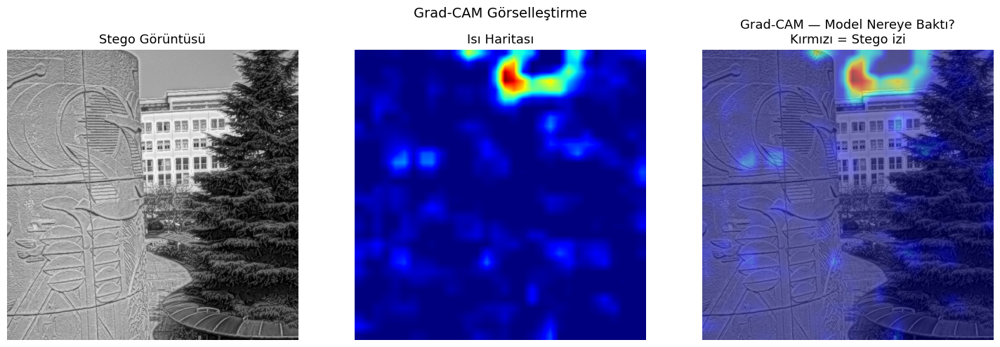

Grad-CAM kaydedildi


In [44]:
!pip install grad-cam -q

import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

donusum = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

stego_klasor = '/content/lsb_subset/test/stego'
goruntu_adi  = sorted(os.listdir(stego_klasor))[0]
goruntu_yolu = os.path.join(stego_klasor, goruntu_adi)

img_rgb   = np.array(Image.open(goruntu_yolu).convert('RGB'))
img_float = np.float32(img_rgb) / 255.0
giris     = donusum(Image.open(goruntu_yolu)).unsqueeze(0).to(device)

model.eval()
hedef_katman = [model.ozellikler[-1]]
cam          = GradCAM(model=model, target_layers=hedef_katman)
isi_haritasi = cam(input_tensor=giris, targets=[ClassifierOutputTarget(1)])[0, :]
h, w         = img_rgb.shape[:2]
isi_haritasi = cv2.resize(isi_haritasi, (w, h))
gorsellestirme = show_cam_on_image(img_float, isi_haritasi, use_rgb=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb);            axes[0].set_title('Stego Görüntüsü', fontsize=13);       axes[0].axis('off')
axes[1].imshow(isi_haritasi, cmap='jet'); axes[1].set_title('Isı Haritası', fontsize=13);    axes[1].axis('off')
axes[2].imshow(gorsellestirme);     axes[2].set_title('Grad-CAM — Model Nereye Baktı?\nKırmızı = Stego izi', fontsize=13); axes[2].axis('off')
plt.suptitle('Grad-CAM Görselleştirme', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/12_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grad-CAM kaydedildi")

## 17. Yanlış Tahminler Galerisi
FP: Cover'ı Stego sandı | FN: Stego'yu Cover sandı

Yanlış Pozitif (FP): 43 — Cover ama Stego sanıldı
Yanlış Negatif (FN): 35 — Stego ama Cover sanıldı


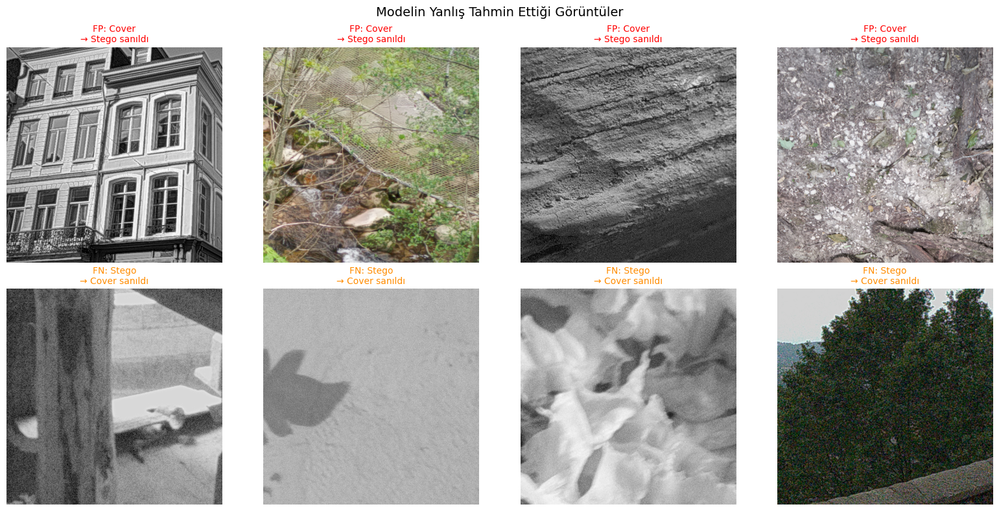

Görsel kaydedildi


In [45]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os

CIKTI_DIR         = '/content/ciktilar'
orig_cover        = '/content/subset/test/cover'
test_cover_klasor = '/content/lsb_subset/test/cover'
test_stego_klasor = '/content/lsb_subset/test/stego'
os.makedirs(CIKTI_DIR, exist_ok=True)

cover_dosyalar = sorted(os.listdir(test_cover_klasor))
stego_dosyalar = sorted(os.listdir(test_stego_klasor))

tahminler_arr = np.array(tahminler)
gercekler_arr = np.array(gercekler)

fp_indeksler = np.where((gercekler_arr == 0) & (tahminler_arr == 1))[0]
fn_indeksler = np.where((gercekler_arr == 1) & (tahminler_arr == 0))[0]

print(f"Yanlış Pozitif (FP): {len(fp_indeksler)} — Cover ama Stego sanıldı")
print(f"Yanlış Negatif (FN): {len(fn_indeksler)} — Stego ama Cover sanıldı")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, idx in enumerate(fp_indeksler[:4]):
    png_dosya = cover_dosyalar[idx % len(cover_dosyalar)]
    jpg_dosya = png_dosya.replace('.png', '.jpg')
    jpg_yolu  = os.path.join(orig_cover, jpg_dosya)
    if os.path.exists(jpg_yolu):
        img = Image.open(jpg_yolu).convert('RGB')
    else:
        img = Image.open(f'{test_cover_klasor}/{png_dosya}').convert('RGB')
    axes[0][i].imshow(img)
    axes[0][i].set_title('FP: Cover\n→ Stego sanıldı', fontsize=10, color='red')
    axes[0][i].axis('off')

for i, idx in enumerate(fn_indeksler[:4]):
    stego_idx = idx - len(cover_dosyalar)
    if 0 <= stego_idx < len(stego_dosyalar):
        png_dosya = stego_dosyalar[stego_idx]
        jpg_dosya = png_dosya.replace('.png', '.jpg')
        jpg_yolu  = os.path.join(orig_cover, jpg_dosya)
        if os.path.exists(jpg_yolu):
            img = Image.open(jpg_yolu).convert('RGB')
        else:
            img = Image.open(f'{test_stego_klasor}/{png_dosya}').convert('RGB')
        axes[1][i].imshow(img)
        axes[1][i].set_title('FN: Stego\n→ Cover sanıldı', fontsize=10, color='darkorange')
        axes[1][i].axis('off')

plt.suptitle('Modelin Yanlış Tahmin Ettiği Görüntüler', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/13_yanlis_tahminler.png', dpi=150, bbox_inches='tight')
plt.show()
print("Görsel kaydedildi")

## 18. Sonuç Özet Tablosu

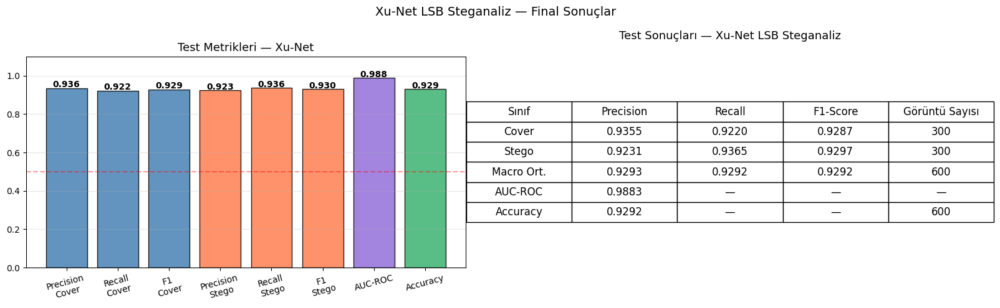


=== Kaydedilen Çıktılar ===
  01_cover_vs_stego.png
  02_sinif_dagilimi.png
  03_temel_goruntu.png
  04_histogramlar.png
  05_lsb_analiz.png
  06_lsb_fark_haritasi.png
  07_bolum_dagilim.png
  08_xunet_mimari.png
  09_egitim_grafigi.png
  10_confusion_matrix.png
  11_roc_egrisi.png
  12_gradcam.png
  13_yanlis_tahminler.png
  14_sonuc_tablosu.png

Sonuç tablosu kaydedildi


In [46]:
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np, os

CIKTI_DIR = '/content/ciktilar'
os.makedirs(CIKTI_DIR, exist_ok=True)

rapor     = classification_report(gercekler, tahminler,
                                   target_names=['Cover','Stego'], output_dict=True)
auc_val   = roc_auc_score(gercekler, olasiliklar)

# Metrik bar grafiği
metrikler = ['Precision\nCover','Recall\nCover','F1\nCover',
             'Precision\nStego','Recall\nStego','F1\nStego','AUC-ROC','Accuracy']
degerler  = [rapor['Cover']['precision'], rapor['Cover']['recall'], rapor['Cover']['f1-score'],
             rapor['Stego']['precision'], rapor['Stego']['recall'], rapor['Stego']['f1-score'],
             auc_val, rapor['accuracy']]
renkler_m = ['steelblue']*3 + ['coral']*3 + ['mediumpurple','mediumseagreen']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
bars = axes[0].bar(metrikler, degerler, color=renkler_m, alpha=0.85, edgecolor='black')
for bar, d in zip(bars, degerler):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{d:.3f}', ha='center', fontsize=10, fontweight='bold')
axes[0].set_ylim(0, 1.1); axes[0].set_title('Test Metrikleri — Xu-Net', fontsize=13)
axes[0].axhline(0.5, color='red', linestyle='--', alpha=0.4)
axes[0].grid(axis='y', alpha=0.3); axes[0].tick_params(axis='x', rotation=15)

axes[1].axis('off')
tablo_veri = [
    ['Cover',      f"{rapor['Cover']['precision']:.4f}", f"{rapor['Cover']['recall']:.4f}", f"{rapor['Cover']['f1-score']:.4f}", '300'],
    ['Stego',      f"{rapor['Stego']['precision']:.4f}", f"{rapor['Stego']['recall']:.4f}", f"{rapor['Stego']['f1-score']:.4f}", '300'],
    ['Macro Ort.', f"{rapor['macro avg']['precision']:.4f}", f"{rapor['macro avg']['recall']:.4f}", f"{rapor['macro avg']['f1-score']:.4f}", '600'],
    ['AUC-ROC',    f'{auc_val:.4f}', '—', '—', '—'],
    ['Accuracy',   f"{rapor['accuracy']:.4f}", '—', '—', '600'],
]
tablo = axes[1].table(cellText=tablo_veri,
                       colLabels=['Sınıf','Precision','Recall','F1-Score','Görüntü Sayısı'],
                       cellLoc='center', loc='center')
tablo.auto_set_font_size(False); tablo.set_fontsize(12); tablo.scale(1.2, 2.2)
axes[1].set_title('Test Sonuçları — Xu-Net LSB Steganaliz', fontsize=13, pad=20)
plt.suptitle('Xu-Net LSB Steganaliz — Final Sonuçlar', fontsize=14)
plt.tight_layout()
plt.savefig(f'{CIKTI_DIR}/14_sonuc_tablosu.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== Kaydedilen Çıktılar ===")
for f in sorted(os.listdir(CIKTI_DIR)):
    print(f"  {f}")
print("\nSonuç tablosu kaydedildi")